In [1]:
from pathlib import Path
import json, math, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from utils.calculations import (
    validate_config, monthly_rate_from_annual, critical_mass, months_to_target,
    simulate, first_positive_profit, binary_minimum, binary_maximum
)
CONFIG = json.loads((ROOT / "data" / "task_02_social_network_config.json").read_text(encoding="utf-8"))
validate_config(CONFIG)

PALETTE = CONFIG["display"]["color_palette"]
SCALE = CONFIG["display"]["display_scale_rub"]
figures_dir = ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
plt.style.use("default")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": CONFIG["display"]["figure_dpi"]})

def fmt(value, digits=2):
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return "не рассчитывается"
    if isinstance(value, float) and math.isinf(value):
        return "не достигается"
    return f"{value:,.{digits}f}".replace(",", " ").replace(".", ",")

def pct(value, digits=1):
    return f"{value:.{digits}%}".replace(".", ",")

def rub(value, digits=2):
    return f"{value:,.{digits}f} руб.".replace(",", " ").replace(".", ",")

monthly_rate = monthly_rate_from_annual(CONFIG["annual_discount_rate"])
CONFIG["monthly_discount_rate"] = monthly_rate
task_opening = f"""# Экзаменационная задача №{CONFIG['task_id']}: {CONFIG['title']}

**Студент:** {CONFIG['student_name']}

**Группа:** {CONFIG['group']}

**Проект:** {CONFIG['project_name']}

**Горизонт анализа:** {CONFIG['analysis_horizon_months']} месяцев

**Эффективная месячная ставка дисконтирования:** {pct(monthly_rate, 3)}"""
display(Markdown(task_opening))

# Экзаменационная задача №2: Расчёт критической массы и ценности социальной сети

**Студент:** Глазков Тимофей Владимирович

**Группа:** БИ ОЗФО5-1

**Проект:** ГородСоцСеть

**Горизонт анализа:** 36 месяцев

**Эффективная месячная ставка дисконтирования:** 0,949%

In [2]:
assignment_text = f"""## Условие задачи

Компания «{CONFIG['project_name']}» запускает социальную сеть для жителей города с населением **{fmt(CONFIG['market_potential_users'])} человек**. Требуется оценить экономическую ценность сети и определить момент достижения критической массы.

**Исходные данные:**

- потенциал рынка — {fmt(CONFIG['market_potential_users'])} пользователей;
- начальная база — {fmt(CONFIG['initial_users'])} пользователей;
- темп прироста до критической массы — {pct(CONFIG['growth_before_critical'])} в месяц;
- темп прироста после критической массы — {pct(CONFIG['growth_after_critical'])} в месяц;
- коэффициент ценности сети — {CONFIG['network_value_coefficient_rub_per_user_squared']} руб./пользователь²;
- затраты на поддержание — {rub(CONFIG['monthly_maintenance_cost_rub'], 0)} в месяц;
- CAC — {rub(CONFIG['cac_rub'], 0)} на пользователя;
- ARPU — {rub(CONFIG['arpu_rub_per_user_month'], 0)} на пользователя в месяц;
- горизонт — {CONFIG['analysis_horizon_months']} месяцев;
- ставка дисконтирования — {pct(CONFIG['annual_discount_rate'])} годовых.

**Задание:** определить критическую массу и срок её достижения; рассчитать ценность сети по закону Мэткалфа, доход и прибыль; определить NPV и влияние темпов роста; найти минимальный ARPU для безубыточности; оценить инвестиции для ускорения достижения критической массы на {CONFIG['analysis_targets']['target_advance_months']} месяцев; сформулировать стратегические рекомендации."""
display(Markdown(assignment_text))

## Условие задачи

Компания «ГородСоцСеть» запускает социальную сеть для жителей города с населением **1 000 000,00 человек**. Требуется оценить экономическую ценность сети и определить момент достижения критической массы.

**Исходные данные:**

- потенциал рынка — 1 000 000,00 пользователей;
- начальная база — 5 000,00 пользователей;
- темп прироста до критической массы — 3,0% в месяц;
- темп прироста после критической массы — 15,0% в месяц;
- коэффициент ценности сети — 0.005 руб./пользователь²;
- затраты на поддержание — 2 000 000 руб, в месяц;
- CAC — 500 руб, на пользователя;
- ARPU — 15 руб, на пользователя в месяц;
- горизонт — 36 месяцев;
- ставка дисконтирования — 12,0% годовых.

**Задание:** определить критическую массу и срок её достижения; рассчитать ценность сети по закону Мэткалфа, доход и прибыль; определить NPV и влияние темпов роста; найти минимальный ARPU для безубыточности; оценить инвестиции для ускорения достижения критической массы на 6 месяцев; сформулировать стратегические рекомендации.

## Экономическая постановка задачи

Рассматривается платформа, у которой доход формируется через ARPU, а затраты состоят из ежемесячного поддержания и CAC для новых пользователей. Необходимо определить, может ли рост пользовательской базы привести к самоподдерживающейся модели на заданном рынке и горизонте.

Модель разделяет три результата: потенциальную сетевую ценность `V(N)`, текущий операционный результат и дисконтированный денежный результат `NPV`. Сетевой эффект важен для стратегической оценки, но сам по себе не является денежным потоком и не заменяет анализ прибыли.

## Теоретическая основа

При росте базы на `g` новые пользователи в месяце `t` равны фактической разнице `Nₜ − Nₜ₋₁`. Если `Nₜ = Nₜ₋₁(1+g)`, то доля новых пользователей в конечной базе равна `g/(1+g)`. Поэтому месячная прибыль имеет вид:

`П(N) = ARPU × N − Cmaint − CAC × (g/(1+g)) × N`.

Критическая масса:

`Nкрит = Cmaint / (ARPU − CAC × g/(1+g))`, если знаменатель положителен.

Потенциальная ценность сетевого эффекта рассчитывается по закону Мэткалфа: `V(N) = k × N²`. NPV определяется как дисконтированная сумма помесячной прибыли. Все три показателя интерпретируются раздельно.

In [3]:
input_rows = [
    ("Потенциал рынка", CONFIG["market_potential_users"], "чел."),
    ("Начальная база", CONFIG["initial_users"], "чел."),
    ("Рост до порога", pct(CONFIG["growth_before_critical"]), "% в месяц"),
    ("Рост после порога", pct(CONFIG["growth_after_critical"]), "% в месяц"),
    ("Коэффициент Мэткалфа", CONFIG["network_value_coefficient_rub_per_user_squared"], "руб./пользователь²"),
    ("Поддержание", rub(CONFIG["monthly_maintenance_cost_rub"], 0), "руб./месяц"),
    ("CAC из условия", rub(CONFIG["cac_rub"], 0), "руб./пользователь"),
    ("Операционный CAC", rub(CONFIG["operational_scenario"]["cac_rub"], 0), "руб./пользователь"),
    ("ARPU", rub(CONFIG["arpu_rub_per_user_month"], 0), "руб./пользователь/месяц"),
    ("Горизонт", CONFIG["analysis_horizon_months"], "месяцев"),
    ("Годовая ставка", pct(CONFIG["annual_discount_rate"]), "% годовых"),
    ("Месячная ставка", pct(monthly_rate, 3), "% в месяц")
]
display(Markdown("## Исходные данные и допущения\n\nВ таблице собраны исходные значения из JSON. Месячная ставка рассчитана из эффективной годовой, чтобы не смешивать два разных способа задания дисконтирования."))
display(pd.DataFrame(input_rows, columns=["Параметр", "Значение", "Единица измерения"]))
display(Markdown(f"**Что показывает таблица.** В расчёте используются {fmt(CONFIG['market_potential_users'])} пользователей рынка, начальная база {fmt(CONFIG['initial_users'])} и горизонт {CONFIG['analysis_horizon_months']} месяцев. Наиболее важные рычаги модели — ARPU, CAC, темп роста и ежемесячное поддержание."))

## Исходные данные и допущения

В таблице собраны исходные значения из JSON. Месячная ставка рассчитана из эффективной годовой, чтобы не смешивать два разных способа задания дисконтирования.

,Параметр,Значение,Единица измерения
0,Потенциал рынка,1000000,чел.
1,Начальная база,5000,чел.
2,Рост до порога,"3,0%",% в месяц
3,Рост после порога,"15,0%",% в месяц
4,Коэффициент Мэткалфа,0.005,руб./пользователь²
5,Поддержание,"2 000 000 руб,",руб./месяц
6,CAC из условия,"500 руб,",руб./пользователь
7,Операционный CAC,"50 руб,",руб./пользователь
8,ARPU,"15 руб,",руб./пользователь/месяц
9,Горизонт,36,месяцев


**Что показывает таблица.** В расчёте используются 1 000 000,00 пользователей рынка, начальная база 5 000,00 и горизонт 36 месяцев. Наиболее важные рычаги модели — ARPU, CAC, темп роста и ежемесячное поддержание.

## Часть 1. Критическая масса и срок её достижения

Сначала рассчитываются два варианта: строгий сценарий с CAC из условия и отдельная операционная гипотеза со сниженным CAC. Второй вариант не подменяет исходную задачу, а показывает, как изменение управляемого параметра влияет на экономику.

In [4]:
strict = simulate(CONFIG)
operational = simulate(CONFIG, cac=CONFIG["operational_scenario"]["cac_rub"])

def reach_text(result):
    m = months_to_target(result["critical"], CONFIG["growth_before_critical"], CONFIG["initial_users"])
    return "не достигается" if (not math.isfinite(result["critical"]) or result["critical"] > CONFIG["market_potential_users"]) else f"{m} мес."

critical_table = pd.DataFrame([
    {"Сценарий": "CAC из условия", "CAC, руб.": CONFIG["cac_rub"], "Маржинальный вклад, руб.": CONFIG["arpu_rub_per_user_month"] - CONFIG["cac_rub"] * CONFIG["growth_before_critical"] / (1 + CONFIG["growth_before_critical"]), "Критическая масса, чел.": "не достигается" if not math.isfinite(strict["critical"]) else fmt(strict["critical"]), "В пределах рынка": "Да" if math.isfinite(strict["critical"]) and strict["critical"] <= CONFIG["market_potential_users"] else "Нет", "Срок": reach_text(strict)},
    {"Сценарий": "Операционная гипотеза", "CAC, руб.": CONFIG["operational_scenario"]["cac_rub"], "Маржинальный вклад, руб.": CONFIG["arpu_rub_per_user_month"] - CONFIG["operational_scenario"]["cac_rub"] * CONFIG["growth_before_critical"] / (1 + CONFIG["growth_before_critical"]), "Критическая масса, чел.": "не достигается" if not math.isfinite(operational["critical"]) else fmt(operational["critical"]), "В пределах рынка": "Да" if math.isfinite(operational["critical"]) and operational["critical"] <= CONFIG["market_potential_users"] else "Нет", "Срок": reach_text(operational)}
])
display(Markdown("### Критическая масса\n\nКритическая масса показывает минимальную базу, при которой текущая месячная прибыль становится неотрицательной при заданном темпе прироста."))
display(critical_table)
strict_reach = "достижима" if math.isfinite(strict["critical"]) and strict["critical"] <= CONFIG["market_potential_users"] else "недостижима в пределах рынка"
oper_reach = "достижима" if math.isfinite(operational["critical"]) and operational["critical"] <= CONFIG["market_potential_users"] else "недостижима в пределах рынка"
display(Markdown(f"**Что показывает таблица.** При CAC из условия критическая масса {strict_reach}; при операционной гипотезе с CAC {rub(CONFIG['operational_scenario']['cac_rub'], 0)} она {oper_reach}. Снижение CAC улучшает экономику, но само по себе ещё не гарантирует достижение порога на горизонте анализа."))
display(Markdown(f"В строгом сценарии знаменатель формулы равен **{rub(CONFIG['arpu_rub_per_user_month'] - CONFIG['cac_rub'] * CONFIG['growth_before_critical']/(1+CONFIG['growth_before_critical']), 2)}** на пользователя. Поэтому исходный CAC не позволяет получить достижимый порог в пределах рынка. Операционный вариант приводится отдельно как управленческая гипотеза."))

### Критическая масса

Критическая масса показывает минимальную базу, при которой текущая месячная прибыль становится неотрицательной при заданном темпе прироста.

,Сценарий,"CAC, руб.","Маржинальный вклад, руб.","Критическая масса, чел.",В пределах рынка,Срок
0,CAC из условия,500,0.436893,"4 577 777,78",Нет,не достигается
1,Операционная гипотеза,50,13.543689,"147 670,25",Да,115 мес.


**Что показывает таблица.** При CAC из условия критическая масса недостижима в пределах рынка; при операционной гипотезе с CAC 50 руб, она достижима. Снижение CAC улучшает экономику, но само по себе ещё не гарантирует достижение порога на горизонте анализа.

В строгом сценарии знаменатель формулы равен **0,44 руб,** на пользователя. Поэтому исходный CAC не позволяет получить достижимый порог в пределах рынка. Операционный вариант приводится отдельно как управленческая гипотеза.

In [5]:
target = operational["critical"]
if math.isfinite(target) and target <= CONFIG["market_potential_users"]:
    exact_month = math.log(target / CONFIG["initial_users"]) / math.log(1 + CONFIG["growth_before_critical"]) if target > CONFIG["initial_users"] else 0
    month_int = math.ceil(exact_month)
    check_months = sorted(set([0, min(12, CONFIG["analysis_horizon_months"]), min(24, CONFIG["analysis_horizon_months"]), min(month_int, CONFIG["analysis_horizon_months"]), CONFIG["analysis_horizon_months"]]))
    check = pd.DataFrame({"Месяц": check_months, "Пользователи по формуле": [min(CONFIG["initial_users"] * (1 + CONFIG["growth_before_critical"]) ** m, CONFIG["market_potential_users"]) for m in check_months]})
    check["Сравнение с порогом"] = np.where(check["Пользователи по формуле"] >= target, "порог достигнут", "ниже порога")
    display(check)
    display(Markdown(f"Точное решение даёт **{exact_month:.2f} месяца**, поэтому по целым периодам порог достигается на **{month_int}-м месяце**. После перехода используется темп {pct(CONFIG['growth_after_critical'])}."))
else:
    display(Markdown("При CAC из условия критическая масса недостижима в пределах рынка. Для операционной гипотезы она также не может быть достигнута на заданном рынке или не существует при текущем наборе параметров."))

,Месяц,Пользователи по формуле,Сравнение с порогом
0,0,5000.000000,ниже порога
1,12,7128.804434,ниже порога
2,24,10163.970532,ниже порога
3,36,14491.391640,ниже порога


Точное решение даёт **114.54 месяца**, поэтому по целым периодам порог достигается на **115-м месяце**. После перехода используется темп 15,0%.

## Часть 2. Ценность сети, доход и прибыль

In [6]:
rows = pd.DataFrame(strict["rows"])
renamed = rows.rename(columns={"month":"Месяц", "users":"Пользователи, чел.", "new_users":"Новые пользователи, чел.", "revenue":"Выручка, руб.", "maintenance":"Поддержание, руб.", "acquisition_cost":"Привлечение, руб.", "profit":"Прибыль, руб.", "network_value":"Ценность сети, руб.", "discount_factor":"Коэффициент дисконтирования", "discounted_profit":"Дисконтированная прибыль, руб."})
display(Markdown("### Помесячная операционная модель\n\nСледующая таблица показывает, как пользовательская база превращается в выручку, затраты, прибыль и потенциальную сетевую ценность. Месяц 0 является исходным состоянием и не содержит затрат на привлечение начальной базы."))
display_df = renamed.head(min(13, len(renamed))).copy()
for col in ["Пользователи, чел.", "Новые пользователи, чел."]:
    display_df[col] = display_df[col].map(lambda x: fmt(x, 0))
for col in ["Выручка, руб.", "Поддержание, руб.", "Привлечение, руб.", "Прибыль, руб.", "Ценность сети, руб.", "Дисконтированная прибыль, руб."]:
    display_df[col] = display_df[col].map(lambda x: rub(x, 2))
display_df["Коэффициент дисконтирования"] = display_df["Коэффициент дисконтирования"].map(lambda x: fmt(x, 4))
display(display_df)
summary = pd.DataFrame([
    ("Пользователи в конце горизонта", fmt(strict["users"][-1]), "чел."),
    ("Ценность сети в конце горизонта", rub(rows["network_value"].iloc[-1], 0), "руб."),
    ("Выручка в конце горизонта", rub(rows["revenue"].iloc[-1], 0), "руб./мес."),
    ("Прибыль в конце горизонта", rub(rows["profit"].iloc[-1], 0), "руб./мес."),
    ("NPV строгого сценария", rub(strict["npv"], 2), "руб.")
], columns=["Показатель", "Значение", "Единица"])
display(summary)
display(Markdown(f"**Что показывает таблица.** К концу горизонта база составляет **{fmt(strict['users'][-1])} пользователей**, месячная прибыль — **{rub(rows['profit'].iloc[-1], 0)}**, а потенциальная ценность сети — **{rub(rows['network_value'].iloc[-1], 0)}**. Потенциальная ценность и прибыль — разные показатели: первая отражает сетевой эффект, вторая — текущий денежный результат."))

### Помесячная операционная модель

Следующая таблица показывает, как пользовательская база превращается в выручку, затраты, прибыль и потенциальную сетевую ценность. Месяц 0 является исходным состоянием и не содержит затрат на привлечение начальной базы.

,Месяц,"Пользователи, чел.","Новые пользователи, чел.","Выручка, руб.","Поддержание, руб.","Привлечение, руб.","Прибыль, руб.",Коэффициент дисконтирования,"Дисконтированная прибыль, руб.","Ценность сети, руб."
0,0,5 000,0,"75 000,00 руб,","2 000 000,00 руб,","0,00 руб,","-1 925 000,00 руб,","1,0000","-1 925 000,00 руб,","125 000,00 руб,"
1,1,5 150,150,"77 250,00 руб,","2 000 000,00 руб,","75 000,00 руб,","-1 997 750,00 руб,","0,9906","-1 978 971,94 руб,","132 612,50 руб,"
2,2,5 304,154,"79 567,50 руб,","2 000 000,00 руб,","77 250,00 руб,","-1 997 682,50 руб,","0,9813","-1 960 304,16 руб,","140 688,60 руб,"
3,3,5 464,159,"81 954,53 руб,","2 000 000,00 руб,","79 567,50 руб,","-1 997 612,98 руб,","0,9721","-1 941 810,50 руб,","149 256,54 руб,"
4,4,5 628,164,"84 413,16 руб,","2 000 000,00 руб,","81 954,53 руб,","-1 997 541,36 руб,","0,9629","-1 923 489,30 руб,","158 346,26 руб,"
5,5,5 796,169,"86 945,56 руб,","2 000 000,00 руб,","84 413,16 руб,","-1 997 467,61 руб,","0,9539","-1 905 338,90 руб,","167 989,55 руб,"
6,6,5 970,174,"89 553,92 руб,","2 000 000,00 руб,","86 945,56 руб,","-1 997 391,63 руб,","0,9449","-1 887 357,69 руб,","178 220,11 руб,"
7,7,6 149,179,"92 240,54 руб,","2 000 000,00 руб,","89 553,92 руб,","-1 997 313,38 руб,","0,9360","-1 869 544,03 руб,","189 073,72 руб,"
8,8,6 334,184,"95 007,76 руб,","2 000 000,00 руб,","92 240,54 руб,","-1 997 232,78 руб,","0,9272","-1 851 896,33 руб,","200 588,30 руб,"
9,9,6 524,190,"97 857,99 руб,","2 000 000,00 руб,","95 007,76 руб,","-1 997 149,77 руб,","0,9185","-1 834 412,99 руб,","212 804,13 руб,"


,Показатель,Значение,Единица
0,Пользователи в конце горизонта,"14 491,39",чел.
1,Ценность сети в конце горизонта,"1 050 002 руб,",руб.
2,Выручка в конце горизонта,"217 371 руб,",руб./мес.
3,Прибыль в конце горизонта,"-1 993 669 руб,",руб./мес.
4,NPV строгого сценария,"-60 632 908,12 руб,",руб.


**Что показывает таблица.** К концу горизонта база составляет **14 491,39 пользователей**, месячная прибыль — **-1 993 669 руб,**, а потенциальная ценность сети — **1 050 002 руб,**. Потенциальная ценность и прибыль — разные показатели: первая отражает сетевой эффект, вторая — текущий денежный результат.

## Часть 3. Эффективность, сценарии и безубыточность

NPV считается по фактическим помесячным денежным потокам за заданный горизонт. Закон Мэткалфа в NPV не добавляется: это оценка потенциальной ценности, а не полученная выручка.

In [7]:
scenario_rows = []
scenario_results = {}
for name, values in CONFIG["scenarios"].items():
    result = simulate(CONFIG, growth_before=values["growth_before"], growth_after=values["growth_after"])
    scenario_results[name] = result
    month = months_to_target(result["critical"], values["growth_before"], CONFIG["initial_users"])
    scenario_rows.append({"Сценарий": name, "Рост до / после": f"{pct(values['growth_before'])} / {pct(values['growth_after'])}", "Пользователи в конце, чел.": fmt(result["users"][-1]), "Критическая масса, чел.": "не достигается" if not math.isfinite(result["critical"]) else fmt(result["critical"]), "Месяц порога": "не достигается" if not math.isfinite(month) or result["critical"] > CONFIG["market_potential_users"] else month, "NPV, руб.": rub(result["npv"], 2)})
scenario_table = pd.DataFrame(scenario_rows)
display(Markdown("### Сценарии темпа роста\n\nТаблица показывает, как изменение темпа роста меняет траекторию базы, положение критического порога и дисконтированный результат. CAC и остальные параметры здесь сохранены на уровне условия задачи."))
display(scenario_table)
best_name = max(scenario_results, key=lambda name: scenario_results[name]["npv"])
worst_name = min(scenario_results, key=lambda name: scenario_results[name]["npv"])
display(Markdown(f"**Что показывает таблица.** Наибольший NPV среди сценариев даёт вариант **{best_name}** ({rub(scenario_results[best_name]['npv'], 0)}), а наименьший — **{worst_name}** ({rub(scenario_results[worst_name]['npv'], 0)}). Следовательно, ускорение роста улучшает результат только в сочетании с достаточной монетизацией и контролем затрат."))

### Сценарии темпа роста

Таблица показывает, как изменение темпа роста меняет траекторию базы, положение критического порога и дисконтированный результат. CAC и остальные параметры здесь сохранены на уровне условия задачи.

,Сценарий,Рост до / после,"Пользователи в конце, чел.","Критическая масса, чел.",Месяц порога,"NPV, руб."
0,Пессимистичный,"2,0% / 10,0%","10 199,44","384 905,66",220,"-59 610 084,82 руб,"
1,Базовый,"3,0% / 15,0%","14 491,39","4 577 777,78",не достигается,"-60 632 908,12 руб,"
2,Оптимистичный,"5,0% / 20,0%","28 959,08",не достигается,не достигается,"-64 314 340,04 руб,"


**Что показывает таблица.** Наибольший NPV среди сценариев даёт вариант **Пессимистичный** (-59 610 085 руб,), а наименьший — **Оптимистичный** (-64 314 340 руб,). Следовательно, ускорение роста улучшает результат только в сочетании с достаточной монетизацией и контролем затрат.

In [8]:
def npv_at_arpu(x): return simulate(CONFIG, arpu=x)["npv"]
def npv_at_cac(x): return simulate(CONFIG, cac=x)["npv"]
def npv_at_growth(x): return simulate(CONFIG, growth_before=x)["npv"]
min_arpu = binary_minimum(npv_at_arpu, CONFIG["scenario_constraints"]["min_arpu_rub"], CONFIG["scenario_constraints"]["max_arpu_rub"])
max_cac = binary_maximum(npv_at_cac, CONFIG["scenario_constraints"]["min_cac_rub"], CONFIG["scenario_constraints"]["max_cac_rub"])
min_growth = binary_minimum(npv_at_growth, CONFIG["scenario_constraints"]["min_growth_before"], CONFIG["scenario_constraints"]["max_growth_before"])
thresholds = pd.DataFrame([
    ("Минимальный ARPU для NPV ≥ 0", "не найден" if not math.isfinite(min_arpu) else rub(min_arpu, 2), "изменяется только ARPU"),
    ("Предельный CAC при NPV ≥ 0", "не найден" if not math.isfinite(max_cac) else rub(max_cac, 2), "изменяется только CAC"),
    ("Минимальный рост до порога для NPV ≥ 0", "не найден" if not math.isfinite(min_growth) else pct(min_growth, 2), "изменяется только темп роста")
], columns=["Пороговый показатель", "Значение", "Интерпретация"])
display(Markdown("### Однопараметрические пороги\n\nЭти ориентиры отвечают на вопрос, какое изменение одного фактора при неизменных остальных параметрах переводит NPV к нулю. Они не являются единственным планом развития."))
display(thresholds)
finite_thresholds = [x for x in [min_arpu, max_cac, min_growth] if math.isfinite(x)]
display(Markdown(f"**Что показывает таблица.** Найдено {len(finite_thresholds)} из 3 однопараметрических порогов. Если порог не найден, одного изменения соответствующего фактора в заданном диапазоне недостаточно — требуется комбинация нескольких мер."))

### Однопараметрические пороги

Эти ориентиры отвечают на вопрос, какое изменение одного фактора при неизменных остальных параметрах переводит NPV к нулю. Они не являются единственным планом развития.

,Пороговый показатель,Значение,Интерпретация
0,Минимальный ARPU для NPV ≥ 0,не найден,изменяется только ARPU
1,Предельный CAC при NPV ≥ 0,не найден,изменяется только CAC
2,Минимальный рост до порога для NPV ≥ 0,не найден,изменяется только темп роста


**Что показывает таблица.** Найдено 0 из 3 однопараметрических порогов. Если порог не найден, одного изменения соответствующего фактора в заданном диапазоне недостаточно — требуется комбинация нескольких мер.

In [9]:
relative = CONFIG["sensitivity"]["relative_values"]
sensitivity_rows = []
for label, key in [("ARPU", "arpu"), ("CAC", "cac"), ("Поддержание", "maintenance"), ("Рост до порога", "growth_before")]:
    for change in relative:
        kwargs = {}
        base = {"arpu": CONFIG["arpu_rub_per_user_month"], "cac": CONFIG["cac_rub"], "maintenance": CONFIG["monthly_maintenance_cost_rub"], "growth_before": CONFIG["growth_before_critical"]}[key]
        kwargs[key] = base * (1 + change)
        result = simulate(CONFIG, **kwargs)
        sensitivity_rows.append({"Фактор": label, "Изменение": pct(change), "NPV, руб.": result["npv"], "NPV к базе, руб.": result["npv"] - strict["npv"]})
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(Markdown("### Чувствительность NPV\n\nВ таблице каждый фактор изменяется отдельно относительно базы. Такой подход показывает направление и масштаб влияния, не выдавая независимый тест одного параметра за комбинированный план."))
sensitivity_display = sensitivity_table.pivot(index="Изменение", columns="Фактор", values="NPV, руб.")
display(sensitivity_display.map(lambda x: rub(x, 0)))
best_sensitivity = sensitivity_table.loc[sensitivity_table["NPV, руб."].idxmax()]
worst_sensitivity = sensitivity_table.loc[sensitivity_table["NPV, руб."].idxmin()]
display(Markdown(f"**Что показывает таблица.** Наиболее благоприятная проверенная комбинация одного фактора — изменение **{best_sensitivity['Фактор']} на {best_sensitivity['Изменение']}**, при котором NPV равен **{rub(best_sensitivity['NPV, руб.'], 0)}**. Наиболее слабый результат даёт изменение **{worst_sensitivity['Фактор']} на {worst_sensitivity['Изменение']}**."))

### Чувствительность NPV

В таблице каждый фактор изменяется отдельно относительно базы. Такой подход показывает направление и масштаб влияния, не выдавая независимый тест одного параметра за комбинированный план.

Фактор,ARPU,CAC,Поддержание,Рост до порога
Изменение,,,,
"-10,0%","-61 033 235 руб,","-60 244 241 руб,","-54 557 957 руб,","-60 283 191 руб,"
"-20,0%","-61 433 562 руб,","-59 855 574 руб,","-48 483 006 руб,","-59 971 926 руб,"
"-30,0%","-61 833 889 руб,","-59 466 907 руб,","-42 408 056 руб,","-59 695 243 руб,"
"0,0%","-60 632 908 руб,","-60 632 908 руб,","-60 632 908 руб,","-60 632 908 руб,"
"10,0%","-60 232 581 руб,","-61 021 575 руб,","-66 707 859 руб,","-61 025 355 руб,"
"20,0%","-59 832 254 руб,","-61 410 242 руб,","-72 782 810 руб,","-61 465 257 руб,"
"30,0%","-59 431 927 руб,","-61 798 909 руб,","-78 857 761 руб,","-61 957 833 руб,"


**Что показывает таблица.** Наиболее благоприятная проверенная комбинация одного фактора — изменение **Поддержание на -30,0%**, при котором NPV равен **-42 408 056 руб,**. Наиболее слабый результат даёт изменение **Поддержание на 30,0%**.

## Часть 4. Комбинированный сценарий и управленческий анализ

In [10]:
combined_cfg = CONFIG["combined_scenario"]
combined = simulate(CONFIG, arpu=combined_cfg["arpu_rub_per_user_month"], cac=combined_cfg["cac_rub"], growth_before=combined_cfg["growth_before_critical"], growth_after=combined_cfg["growth_after_critical"], maintenance=combined_cfg["monthly_maintenance_cost_rub"])
comparison = pd.DataFrame([
    ("ARPU", rub(CONFIG["arpu_rub_per_user_month"], 0), rub(combined_cfg["arpu_rub_per_user_month"], 0), "повышение монетизации"),
    ("CAC", rub(CONFIG["cac_rub"], 0), rub(combined_cfg["cac_rub"], 0), "реферальный и локальный рост"),
    ("Рост до порога", pct(CONFIG["growth_before_critical"]), pct(combined_cfg["growth_before_critical"]), "ускорение привлечения"),
    ("Поддержание", rub(CONFIG["monthly_maintenance_cost_rub"], 0), rub(combined_cfg["monthly_maintenance_cost_rub"], 0), "локальный пилот"),
    ("NPV", rub(strict["npv"], 2), rub(combined["npv"], 2), "результат полного пересчёта")
], columns=["Параметр", "Текущая модель", "Комбинированный сценарий", "Экономический смысл"])
display(Markdown(f"### Комбинированный сценарий «{combined_cfg['name']}»\n\nЭто один согласованный вариант достижения целевого результата, а не единственно возможное решение. Все его параметры загружаются из JSON и одновременно участвуют в полном пересчёте."))
display(comparison)
combined_status = "положительный" if combined["npv"] >= CONFIG["analysis_targets"]["break_even_npv_rub"] else "отрицательный"
display(Markdown(f"NPV комбинированного сценария составляет **{rub(combined['npv'], 2)}**, то есть является **{combined_status}** относительно нулевой точки."))

### Комбинированный сценарий «Локальный пилот с улучшенной экономикой»

Это один согласованный вариант достижения целевого результата, а не единственно возможное решение. Все его параметры загружаются из JSON и одновременно участвуют в полном пересчёте.

,Параметр,Текущая модель,Комбинированный сценарий,Экономический смысл
0,ARPU,"15 руб,","30 руб,",повышение монетизации
1,CAC,"500 руб,","20 руб,",реферальный и локальный рост
2,Рост до порога,"3,0%","15,0%",ускорение привлечения
3,Поддержание,"2 000 000 руб,","200 000 руб,",локальный пилот
4,NPV,"-60 632 908,12 руб,","114 994 736,77 руб,",результат полного пересчёта


NPV комбинированного сценария составляет **114 994 736,77 руб,**, то есть является **положительный** относительно нулевой точки.

In [11]:
lever_rows = []
for name, kwargs in [
    ("Только ARPU на пороге", {"arpu": min_arpu}),
    ("Только CAC на пороге", {"cac": max_cac}),
    ("Только рост на пороге", {"growth_before": min_growth}),
    ("Только поддержание = 0", {"maintenance": 0.0})
]:
    if any(not math.isfinite(v) for v in kwargs.values()):
        value = math.nan
    else:
        value = simulate(CONFIG, **kwargs)["npv"]
    lever_rows.append({"Ограниченный сценарий": name, "NPV, руб.": "не достигается" if isinstance(value, float) and math.isnan(value) else rub(value, 2), "Интерпретация": "нужны несколько одновременных изменений" if isinstance(value, float) and math.isnan(value) else ("NPV неотрицателен" if value >= 0 else "одного изменения недостаточно")})
display(Markdown("### Анализ ограничений\n\nЕсли один из рычагов нельзя изменить, модель проверяет альтернативу. Это помогает отличить параметр, которого достаточно для выхода к нулю, от ситуации, где требуется комбинация мер."))
display(pd.DataFrame(lever_rows))
nonnegative_limited = sum("NPV неотрицателен" in row["Интерпретация"] for row in lever_rows)
display(Markdown(f"**Что показывает таблица.** В {nonnegative_limited} из {len(lever_rows)} проверенных ограниченных вариантов одного доступного изменения достаточно для неотрицательного NPV. В остальных случаях понадобится сочетание нескольких управляемых параметров."))

### Анализ ограничений

Если один из рычагов нельзя изменить, модель проверяет альтернативу. Это помогает отличить параметр, которого достаточно для выхода к нулю, от ситуации, где требуется комбинация мер.

,Ограниченный сценарий,"NPV, руб.",Интерпретация
0,Только ARPU на пороге,не достигается,нужны несколько одновременных изменений
1,Только CAC на пороге,не достигается,нужны несколько одновременных изменений
2,Только рост на пороге,не достигается,нужны несколько одновременных изменений
3,Только поддержание = 0,"-221 961 093,91 руб,",одного изменения недостаточно


**Что показывает таблица.** В 0 из 4 проверенных ограниченных вариантов одного доступного изменения достаточно для неотрицательного NPV. В остальных случаях понадобится сочетание нескольких управляемых параметров.

In [12]:
oper_target = operational["critical"]
if math.isfinite(oper_target) and oper_target <= CONFIG["market_potential_users"]:
    base_month = months_to_target(oper_target, CONFIG["growth_before_critical"], CONFIG["initial_users"])
    target_month = max(1, base_month - CONFIG["analysis_targets"]["target_advance_months"])
    users_at_target = min(CONFIG["initial_users"] * (1 + CONFIG["growth_before_critical"]) ** target_month, CONFIG["market_potential_users"])
    additional = max(oper_target - users_at_target, 0)
    marketing_investment = additional * CONFIG["operational_scenario"]["cac_rub"]
    investment_text = rub(marketing_investment, 2)
else:
    base_month = target_month = additional = marketing_investment = math.inf
    investment_text = "не определяется: порог недостижим в пределах рынка"
marketing = pd.DataFrame([
    ("Исходный строгий сценарий", "Порог недостижим в пределах рынка" if not math.isfinite(strict["critical"]) or strict["critical"] > CONFIG["market_potential_users"] else "достижим", "инвестиции не рассчитываются без достижимой цели"),
    ("Операционная гипотеза", "не достигается" if not math.isfinite(base_month) else f"{base_month} мес.", investment_text),
    ("Целевое ускорение", "не определяется" if not math.isfinite(target_month) else f"{target_month} мес.", "рассчитывается по дополнительным пользователям")
], columns=["Сценарий", "Срок", "Инвестиции / вывод"])
display(Markdown(f"### Инвестиции для ускорения\n\nВопрос об ускорении на {CONFIG['analysis_targets']['target_advance_months']} месяцев имеет численный ответ только при достижимой критической массе. Поэтому сначала проверяется достижимость порога, затем оцениваются недостающие пользователи и расходы на их привлечение."))
display(marketing)
display(Markdown(f"**Что показывает таблица.** Строгий сценарий не даёт достижимой цели. Для операционной гипотезы расчёт инвестиций возможен только тогда, когда критическая масса находится внутри рынка; иначе маркетинговый бюджет не устраняет саму проблему недостижимого порога."))

### Инвестиции для ускорения

Вопрос об ускорении на 6 месяцев имеет численный ответ только при достижимой критической массе. Поэтому сначала проверяется достижимость порога, затем оцениваются недостающие пользователи и расходы на их привлечение.

,Сценарий,Срок,Инвестиции / вывод
0,Исходный строгий сценарий,Порог недостижим в пределах рынка,инвестиции не рассчитываются без достижимой цели
1,Операционная гипотеза,115 мес.,"1 114 523,64 руб,"
2,Целевое ускорение,109 мес.,рассчитывается по дополнительным пользователям


**Что показывает таблица.** Строгий сценарий не даёт достижимой цели. Для операционной гипотезы расчёт инвестиций возможен только тогда, когда критическая масса находится внутри рынка; иначе маркетинговый бюджет не устраняет саму проблему недостижимого порога.

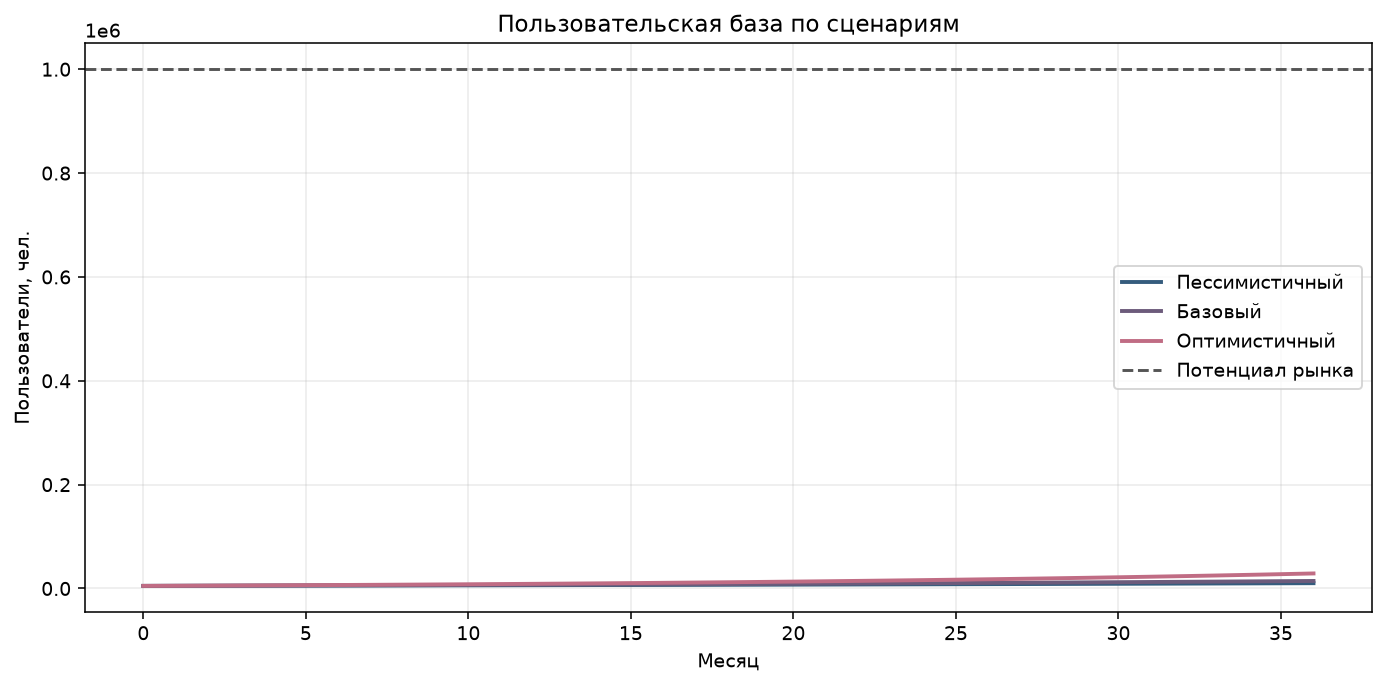

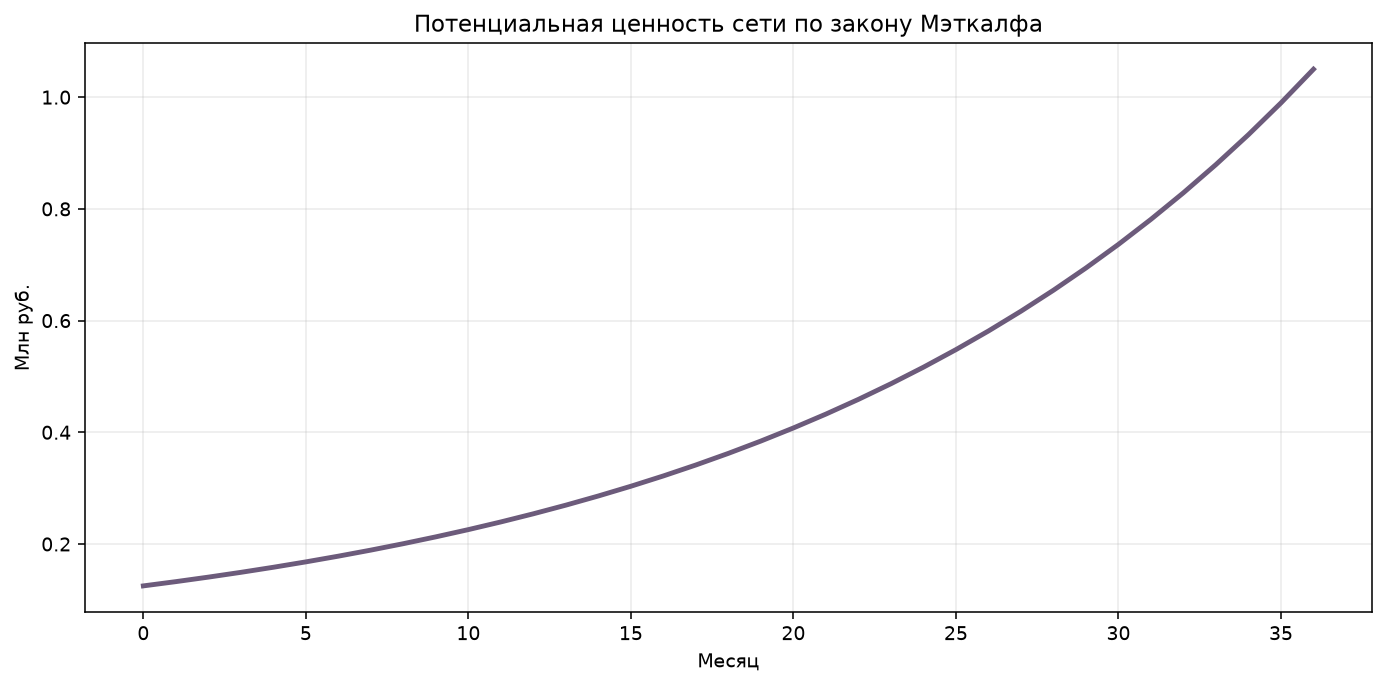

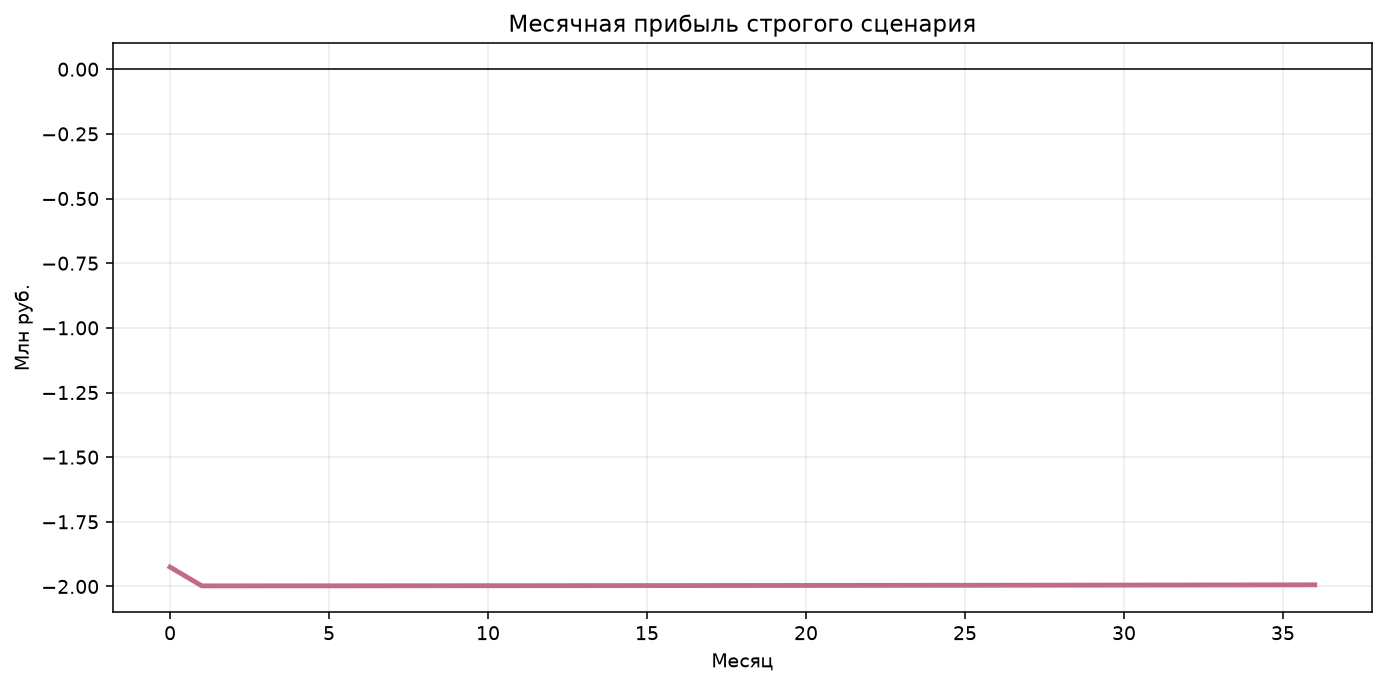

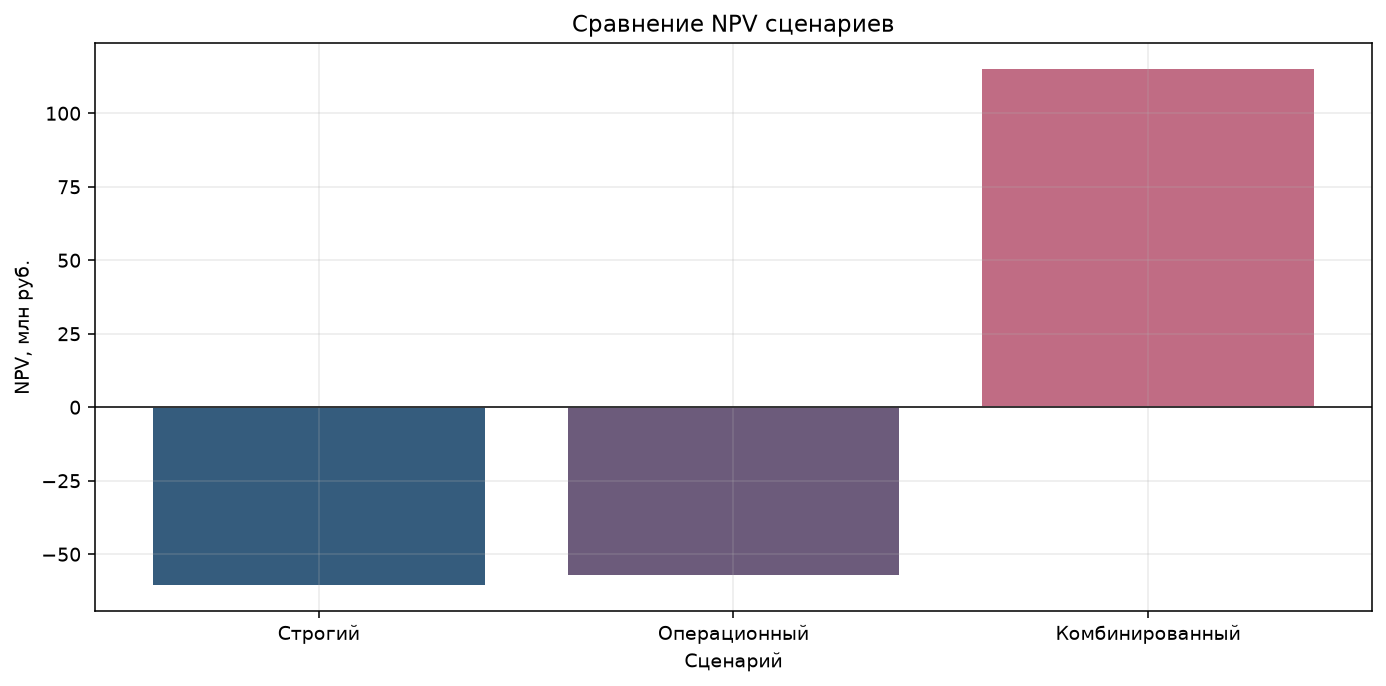

Графики показывают соответственно изменение пользовательской базы, потенциальной сетевой ценности, месячного денежного результата и NPV сценариев. Нулевая линия на денежных графиках отделяет прибыль от убытка.

In [13]:
# График 1: пользователи по сценариям
fig, ax = plt.subplots(figsize=(CONFIG["display"]["figure_width"], CONFIG["display"]["figure_height"]))
for idx, (name, result) in enumerate(scenario_results.items()):
    ax.plot([r["month"] for r in result["rows"]], result["users"], label=name, color=PALETTE[idx], linewidth=2)
ax.axhline(CONFIG["market_potential_users"], color="#555555", linestyle="--", label="Потенциал рынка")
ax.set(title="Пользовательская база по сценариям", xlabel="Месяц", ylabel="Пользователи, чел."); ax.legend(); fig.tight_layout(); fig.savefig(figures_dir / "task_02_users_scenarios.png", bbox_inches="tight"); plt.show()

# График 2: ценность сети
fig, ax = plt.subplots(figsize=(CONFIG["display"]["figure_width"], CONFIG["display"]["figure_height"]))
ax.plot(rows["month"], rows["network_value"] / SCALE, color=PALETTE[1], linewidth=2.5)
ax.set(title="Потенциальная ценность сети по закону Мэткалфа", xlabel="Месяц", ylabel="Млн руб."); fig.tight_layout(); fig.savefig(figures_dir / "task_02_network_value.png", bbox_inches="tight"); plt.show()

# График 3: операционная прибыль
fig, ax = plt.subplots(figsize=(CONFIG["display"]["figure_width"], CONFIG["display"]["figure_height"]))
ax.plot(rows["month"], rows["profit"] / SCALE, color=PALETTE[2], linewidth=2.5); ax.axhline(0, color="#333333", linewidth=1)
ax.set(title="Месячная прибыль строгого сценария", xlabel="Месяц", ylabel="Млн руб."); fig.tight_layout(); fig.savefig(figures_dir / "task_02_profit.png", bbox_inches="tight"); plt.show()

# График 4: сравнение NPV
fig, ax = plt.subplots(figsize=(CONFIG["display"]["figure_width"], CONFIG["display"]["figure_height"]))
npv_names = ["Строгий", "Операционный", "Комбинированный"]; npv_values = [strict["npv"]/SCALE, operational["npv"]/SCALE, combined["npv"]/SCALE]
ax.bar(npv_names, npv_values, color=PALETTE[:3]); ax.axhline(0, color="#333333", linewidth=1)
ax.set(title="Сравнение NPV сценариев", xlabel="Сценарий", ylabel="NPV, млн руб."); fig.tight_layout(); fig.savefig(figures_dir / "task_02_npv_scenarios.png", bbox_inches="tight"); plt.show()

display(Markdown("Графики показывают соответственно изменение пользовательской базы, потенциальной сетевой ценности, месячного денежного результата и NPV сценариев. Нулевая линия на денежных графиках отделяет прибыль от убытка."))

In [14]:
base_status = "положительный" if strict["npv"] >= 0 else "отрицательный"
if strict["npv"] < 0:
    recommendation = (
        f"Для выхода из отрицательного NPV необходимо обеспечить ARPU не ниже {rub(min_arpu, 2)}, "
        f"CAC не выше {rub(max_cac, 2) if math.isfinite(max_cac) else 'порог не найден в заданном диапазоне'} "
        f"и темп роста до порога не ниже {pct(min_growth, 2) if math.isfinite(min_growth) else 'порог не найден в заданном диапазоне'}. "
        "Практически более реалистичен комбинированный сценарий."
        if math.isfinite(min_arpu) else
        "Одного изменения ARPU недостаточно: в заданном диапазоне однопараметрический порог ARPU не найден. "
        "Для выхода из отрицательного NPV требуется совместное изменение нескольких параметров — ARPU, CAC, темпа роста и/или затрат на поддержание. "
        "Практически более реалистичен комбинированный сценарий."
    )
else:
    recommendation = "Сохранять текущую модель можно только при подтверждении положительного NPV фактическими когортными данными."
final_conclusion = f"""## Итоговый вывод и рекомендации

**Базовый результат.** При параметрах условия NPV проекта за {CONFIG['analysis_horizon_months']} месяцев является **{base_status}** и составляет **{rub(strict['npv'], 2)}**. Критическая масса в строгом сценарии {'недостижима в пределах рынка' if not math.isfinite(strict['critical']) or strict['critical'] > CONFIG['market_potential_users'] else 'достижима в пределах рынка'}.

**Однопараметрический анализ.** Расчётные пороги показывают, какое изменение одного фактора могло бы привести NPV к нулю при неизменности остальных параметров. Это диагностические ориентиры, а не готовый план.

**Комбинированный анализ.** Сценарий «{combined_cfg['name']}» даёт NPV **{rub(combined['npv'], 2)}**. Он одновременно меняет ARPU, CAC, темп роста и затраты на поддержание, поэтому его нужно проверять по фактическим данным.

**Денежная интерпретация.** Закон Мэткалфа показывает потенциальную ценность сетевого эффекта, но не добавляется к NPV как денежный доход. Решение о масштабировании принимается по прибыли и NPV.

**Управленческая рекомендация.** {recommendation}"""
display(Markdown(final_conclusion))

## Итоговый вывод и рекомендации

**Базовый результат.** При параметрах условия NPV проекта за 36 месяцев является **отрицательный** и составляет **-60 632 908,12 руб,**. Критическая масса в строгом сценарии недостижима в пределах рынка.

**Однопараметрический анализ.** Расчётные пороги показывают, какое изменение одного фактора могло бы привести NPV к нулю при неизменности остальных параметров. Это диагностические ориентиры, а не готовый план.

**Комбинированный анализ.** Сценарий «Локальный пилот с улучшенной экономикой» даёт NPV **114 994 736,77 руб,**. Он одновременно меняет ARPU, CAC, темп роста и затраты на поддержание, поэтому его нужно проверять по фактическим данным.

**Денежная интерпретация.** Закон Мэткалфа показывает потенциальную ценность сетевого эффекта, но не добавляется к NPV как денежный доход. Решение о масштабировании принимается по прибыли и NPV.

**Управленческая рекомендация.** Одного изменения ARPU недостаточно: в заданном диапазоне однопараметрический порог ARPU не найден. Для выхода из отрицательного NPV требуется совместное изменение нескольких параметров — ARPU, CAC, темпа роста и/или затрат на поддержание. Практически более реалистичен комбинированный сценарий.

## Ограничения модели

В условии не заданы отток, сезонность, налоги, капитальные затраты, переменная маржа, различия между зарегистрированными и активными пользователями и изменение CAC при масштабировании. Поэтому расчёт является учебной экономической моделью. Следующий шаг для реального решения — заменить допущения наблюдаемыми когортными данными и повторить расчёт.

In [16]:
%%capture
# Экспорт выполненного Notebook в HTML-отчёт
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_02_report task_02_social_network.ipynb